# 1. Revisar el dataset limpio de V0.1
Partimos directamente de **V0.1/LICIT_depurando_sinNulos.feather**, preparado por ti.
No se releen los CSV ni se repite tu depuración. Solo se comprueba su estado y
se prepara una copia de variables para comparar modelos. El archivo original no cambia.
Selecciona el kernel V0.2/.venv/Scripts/python.exe y ejecuta las celdas en orden.

In [1]:
from pathlib import Path
import os
BASE = Path.cwd().resolve()
if not (BASE / "02_Comparacion_de_Modelos.ipynb").exists() and (BASE / "V0.2" / "02_Comparacion_de_Modelos.ipynb").exists():
    BASE = BASE / "V0.2"
if not (BASE / "02_Comparacion_de_Modelos.ipynb").exists():
    raise FileNotFoundError("Abre el proyecto desde la raíz o desde V0.2.")
os.chdir(BASE)
import pandas as pd
import numpy as np
import json
import joblib
import matplotlib.pyplot as plt
from IPython.display import display
FUENTE = BASE.parent / "V0.1" / "LICIT_depurando_sinNulos.feather"
SALIDA = BASE / "resultados_dataset_limpio"
SALIDA.mkdir(exist_ok=True)
print("Dataset de entrada:", FUENTE)

Dataset de entrada: D:\Licit\1\ML-SmartBids\V0.1\LICIT_depurando_sinNulos.feather


## 1.1. Dimensiones, nulos, tipos y objetivo
Seleccionada ya está codificada: 1 significa seleccionada, 0 no seleccionada.
Conservamos la codificación de sector, tipo y región que ya contiene tu archivo.

In [2]:
original = pd.read_feather(FUENTE)
print("Dimensiones:", original.shape)
display(original.head())
display(pd.DataFrame({"tipo": original.dtypes.astype(str), "nulos": original.isna().sum()}))
display(original.Seleccionada.value_counts().sort_index().to_frame("filas"))
print(f"Memoria: {original.memory_usage(deep=True).sum()/1024**2:.1f} MB")

Dimensiones: (2248494, 49)


,CodigoUnidad,CantidadReclamos,MontoEstimado,NumeroOferentes,CodigoProductoONU,Cantidad,Cantidad Ofertada,Valor Total Ofertado,Seleccionada,DuracionProceso,...,Region_Región de La Araucanía,Region_Región de Los Lagos,Region_Región de Los Ríos,Region_Región de Magallanes y de la Antártica Chilena,Region_Región de Tarapacá,Region_Región de Valparaíso,Region_Región de Ñuble,Region_Región del Biobío,Region_Región del Libertador General Bernardo O'Higgins,Region_Región del Maule
0,1604,3521,645753500.0,10,42221504,60.0,60.0,486000.0,1,32,...,0,0,0,0,0,1,0,0,0,0
1,1604,3521,645753500.0,10,42221504,60.0,60.0,486000.0,1,32,...,0,0,0,0,0,1,0,0,0,0
2,1604,3521,645753500.0,10,42221504,60.0,60.0,599400.0,0,32,...,0,0,0,0,0,1,0,0,0,0
3,1604,3521,645753500.0,10,42221504,60.0,60.0,599400.0,0,32,...,0,0,0,0,0,1,0,0,0,0
4,1604,3521,645753500.0,10,42221504,60.0,60.0,486000.0,1,32,...,0,0,0,0,0,1,0,0,0,0


,tipo,nulos
CodigoUnidad,uint32,0
CantidadReclamos,int16,0
MontoEstimado,float64,0
NumeroOferentes,int16,0
CodigoProductoONU,int32,0
Cantidad,float64,0
Cantidad Ofertada,float64,0
Valor Total Ofertado,float64,0
Seleccionada,int8,0
DuracionProceso,int16,0


,filas
Seleccionada,
0,1891337
1,357157


Memoria: 186.6 MB


## 1.2. Ajustes mínimos para el entrenamiento
Se excluyen filas con montos o cantidades de oferta no positivos y objetivos inválidos.
No se eliminan todos los duplicados: vectores idénticos se mantendrán en el mismo grupo.
NumeroOferentes y CantidadReclamos pueden reflejar información posterior al envío.
DuracionProceso también se excluye porque no podemos comprobar aquí si representa
la duración anunciada inicialmente o la final.

Los códigos se tratan como categorías. Montos y cantidades reciben log(1+x).
La conversión monetaria hecha en V0.1 se hereda; este archivo ya no permite
comprobar la moneda original de la oferta ni rehacerla con seguridad.

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, precision_recall_curve,
    brier_score_loss, log_loss)
from pathlib import Path
import json
import time
import warnings
import joblib
import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.frozen import FrozenEstimator
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
EXCLUIR = ["NumeroOferentes", "CantidadReclamos", "DuracionProceso"]
CODIGOS = ["CodigoUnidad", "CodigoProductoONU"]

def preparar_limpio(ruta):
    """Verifica el dataset del usuario; no repite su cadena de depuración."""
    df = pd.read_feather(ruta)
    requeridas = ["Seleccionada", "Valor Total Ofertado", "Cantidad Ofertada", "Cantidad"]
    faltan = sorted(set(requeridas) - set(df.columns))
    if faltan:
        raise ValueError(f"Faltan columnas en el Feather limpio: {faltan}")
    antes = len(df)
    valido = df.Seleccionada.isin([0, 1])
    valido &= df[["Valor Total Ofertado", "Cantidad Ofertada", "Cantidad"]].gt(0).all(axis=1)
    df = df.loc[valido].copy().reset_index(drop=True)
    y = df.pop("Seleccionada").astype("int8")
    X = df.drop(columns=EXCLUIR, errors="ignore")
    # Los montos ya están transformados por V0.1. No se reconvierten monedas.
    # No asumimos que el presupuesto global es un presupuesto por ítem.
    for columna in ["MontoEstimado", "Valor Total Ofertado", "Cantidad", "Cantidad Ofertada"]:
        if columna in X:
            X[columna] = np.log1p(X[columna].clip(lower=0))
    for columna in CODIGOS:
        if columna in X:
            X[columna] = X[columna].astype("string").fillna("sin_codigo").astype(str)
    numericas = X.select_dtypes(include="number").columns
    X[numericas] = X[numericas].replace([np.inf, -np.inf], np.nan)
    # La huella NO incluye el objetivo: vectores idénticos se mantienen juntos
    # aunque sus etiquetas sean diferentes. No representa una licitación real.
    grupos = pd.util.hash_pandas_object(X, index=False).to_numpy()
    auditoria = {"archivo": str(Path(ruta).resolve()), "filas_entrada": antes,
                 "filas_utilizadas": len(X), "filas_excluidas": antes-len(X),
                 "motivo_exclusion": "Objetivo inválido o monto/cantidad de oferta no positivo",
                 "predictores": X.columns.tolist(), "excluidas_por_disponibilidad": EXCLUIR,
                 "limitacion": "Sin identificador de licitación ni fechas exactas; no se verifica generalización temporal por licitación.",
                 "grupos": "Huella de predictores, no ID de licitación",
                 "transformacion": "log1p en montos y cantidades; códigos como categorías"}
    return X, y, grupos, auditoria

# Funciones auxiliares incluidas aquí: no se requieren módulos .py del proyecto.
def catalogo(incluir_random_forest=False):
    """Mismos tres algoritmos del trabajo original, sin ofertas sintéticas."""
    modelos = {
        "Regresion_Logistica": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
        "Arbol_Decision": DecisionTreeClassifier(max_depth=10, min_samples_leaf=50,
                                                class_weight="balanced", random_state=42),
        "Red_Neuronal_MLP": MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=100,
                                          early_stopping=True, n_iter_no_change=8,
                                          random_state=42),
    }
    if incluir_random_forest:
        modelos["Random_Forest"] = RandomForestClassifier(
            n_estimators=100, max_depth=14, min_samples_leaf=30,
            class_weight="balanced_subsample", random_state=42, n_jobs=2)
    return modelos

def metricas(y, p, umbral):
    pred = p >= umbral
    return {"F1": float(f1_score(y, pred, zero_division=0)),
            "precision": float(precision_score(y, pred, zero_division=0)),
            "recall": float(recall_score(y, pred, zero_division=0)),
            "ROC_AUC": float(roc_auc_score(y, p)),
            "average_precision": float(average_precision_score(y, p)),
            "Brier": float(brier_score_loss(y, p)),
            "log_loss": float(log_loss(y, p)),
            "matriz_confusion_orden_0_1": confusion_matrix(y, pred, labels=[0, 1]).tolist()}

def umbral_f1(y, p):
    precision, recall, thresholds = precision_recall_curve(y, p)
    den = precision[:-1] + recall[:-1]
    f1 = np.divide(2 * precision[:-1] * recall[:-1], den, out=np.zeros_like(den), where=den > 0)
    return float(thresholds[int(np.argmax(f1))])

In [4]:
X, y, grupos, auditoria = preparar_limpio(FUENTE)
display(pd.Series(auditoria))
display(X.head())
# El conjunto se mantiene en memoria; el archivo de V0.1 permanece intacto.

archivo                         D:\Licit\1\ML-SmartBids\V0.1\LICIT_depurando_s...
filas_entrada                                                             2248494
filas_utilizadas                                                          2105614
filas_excluidas                                                            142880
motivo_exclusion                Objetivo inválido o monto/cantidad de oferta n...
predictores                     [CodigoUnidad, MontoEstimado, CodigoProductoON...
excluidas_por_disponibilidad    [NumeroOferentes, CantidadReclamos, DuracionPr...
limitacion                      Sin identificador de licitación ni fechas exac...
grupos                                 Huella de predictores, no ID de licitación
transformacion                  log1p en montos y cantidades; códigos como cat...
dtype: object

,CodigoUnidad,MontoEstimado,CodigoProductoONU,Cantidad,Cantidad Ofertada,Valor Total Ofertado,AnioPublicacion,MesPublicacion,DiaSemanaPublicacion,sector_FFAA,...,Region_Región de La Araucanía,Region_Región de Los Lagos,Region_Región de Los Ríos,Region_Región de Magallanes y de la Antártica Chilena,Region_Región de Tarapacá,Region_Región de Valparaíso,Region_Región de Ñuble,Region_Región del Biobío,Region_Región del Libertador General Bernardo O'Higgins,Region_Región del Maule
0,1604,20.285928,42221504,4.110874,4.110874,13.093966,2024,1,3,0,...,0,0,0,0,0,1,0,0,0,0
1,1604,20.285928,42221504,4.110874,4.110874,13.093966,2024,1,3,0,...,0,0,0,0,0,1,0,0,0,0
2,1604,20.285928,42221504,4.110874,4.110874,13.303686,2024,1,3,0,...,0,0,0,0,0,1,0,0,0,0
3,1604,20.285928,42221504,4.110874,4.110874,13.303686,2024,1,3,0,...,0,0,0,0,0,1,0,0,0,0
4,1604,20.285928,42221504,4.110874,4.110874,13.093966,2024,1,3,0,...,0,0,0,0,0,1,0,0,0,0


## 1.3. Exploración visual
El gráfico muestra la distribución de clases del conjunto que entrará en la comparación.
No se balancean validación ni prueba. La escala del monto mostrado es logarítmica.

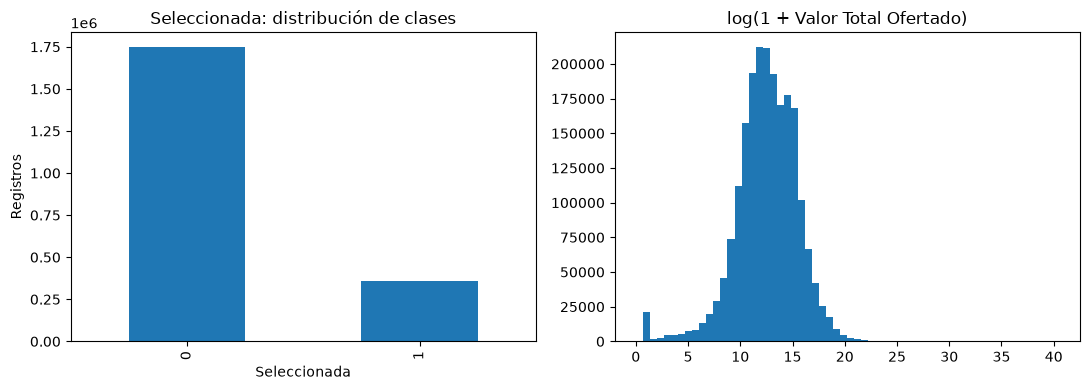

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
y.value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set_title("Seleccionada: distribución de clases")
axes[0].set_ylabel("Registros")
axes[1].hist(X["Valor Total Ofertado"], bins=60)
axes[1].set_title("log(1 + Valor Total Ofertado)")
fig.tight_layout()
plt.show()

## 1.4. Límite de la evaluación
El archivo no tiene CodigoExterno ni fechas exactas. No podemos reconstruir
licitaciones completas ni comprobar generalización temporal. La comparación
será exploratoria con grupos de predictores idénticos, que NO equivalen a una
licitación. Continúa en 02_Comparacion_de_Modelos.ipynb.